In [1]:
%reload_ext autoreload
%autoreload 2

import time
import matplotlib.pyplot as plt
from multi_reference import FastMultiViewMasaCtrlInpainter
from PIL import Image
from PIL import ImageFilter
import numpy as np

inpainter = FastMultiViewMasaCtrlInpainter(
    inpaint_model_id='sd-legacy/stable-diffusion-inpainting',
    device='cuda',
    hook_blocks=('up_blocks.2', 'up_blocks.3'),
    batch_chunk_size=8,
)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_inpaint.StableDiffusionInpaintPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
/home/izidorg/miniconda3/envs/inpainting/lib/python3.12/site-packages/diffusers/pipelines/pipeline_utils.py:2273: FutureWarning: `enable_vae_slicing` is deprecated and will be removed in version 0.40.0. Calling `enable_vae_slicing()` on a `StableDiffusionInpaintPipeline` is deprecated and this method will be removed in a future ver

In [89]:
ref_imgs = [Image.open('references/hair.jpg')]
ref_msks = [Image.new('L', ref_imgs[0].size, 255)]

def fidelity_func(s: int, n: int) -> float:
    return float(np.linspace(0.0, 0.99, n)[s])

def bias_func(s: int, n: int) -> float:
    return float(np.linspace(-12, -2.5, n)[s])

inpainter.clear_references()

cache_stats = inpainter.set_references(
    reference_image=ref_imgs,
    reference_mask=ref_msks,
    angles_deg=tuple(np.linspace(-50.0, 50.0, 18)),
    scales=(1,),
    width=512,
    height=512,
    num_inference_steps=35,
    switch_step=1,
    funnel_step=10,
    highres_start_step=4,
    write_stride=2,
    bg_suppress_bias=bias_func,
    isolate_reference=True,
    ref_seed=2,
    max_pinned_gb=4.0,
    min_free_ram_gb=4.0,
    quantize_cache=True,
)

cache_stats

{'pinned_mb': 1569.72,
 'ram_mb': 0.0,
 'ssd_mb': 0.0,
 'total_mb': 1569.72,
 'num_entries': 108}

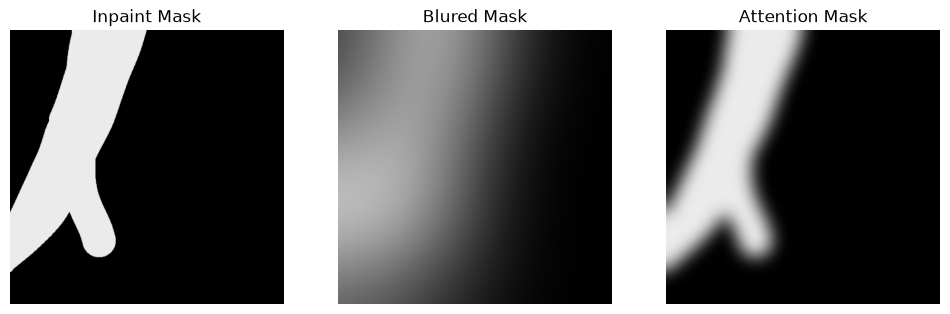

In [118]:
init_img = Image.open('assets/src.jpg')
inpaint_msk = Image.open('assets/hair_mask_2.png')
attn_msk = inpaint_msk.filter(ImageFilter.GaussianBlur(15))



def gradient_mask(
    mask: Image.Image | np.ndarray,
    start: float = 1.0,
    end: float = 0.4,
    vertical: bool = True,
    max_val: float | None = None,
) -> Image.Image:
    arr = np.array(mask.convert('L'), dtype=np.float32) if isinstance(mask, Image.Image) else np.asarray(mask, dtype=np.float32)
    n = arr.shape[0] if vertical else arr.shape[1]
    ramp = np.linspace(start, end, n, dtype=np.float32)
    if max_val is not None:
        ramp = np.minimum(ramp, max_val)
    grid = ramp[:, None] if vertical else ramp[None, :]
    out = np.rint((arr > 127) * grid * 255.0).clip(0, 255).astype(np.uint8)
    return Image.fromarray(out, mode='L')


# blured_mask = gradient_mask(inpaint_msk, start=0.7, end=0.35).filter(ImageFilter.MaxFilter(25)).filter(ImageFilter.GaussianBlur(20))
blured_mask = inpaint_msk.filter(ImageFilter.MaxFilter(55)).filter(ImageFilter.GaussianBlur(99))
# attn_msk = attn_msk.filter(ImageFilter.MaxFilter(25)).filter(ImageFilter.GaussianBlur(20))

p, ax = plt.subplots(1, 3, figsize=(4 * 3, 4))
ax[0].imshow(inpaint_msk)
ax[0].set_title('Inpaint Mask')
ax[0].axis('off')
ax[1].imshow(blured_mask, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('Blured Mask')
ax[1].axis('off')
ax[2].imshow(attn_msk)
ax[2].set_title('Attention Mask')
ax[2].axis('off')

p.show()

  0%|          | 0/35 [00:00<?, ?it/s]

  0%|          | 0/35 [00:00<?, ?it/s]

  0%|          | 0/35 [00:00<?, ?it/s]

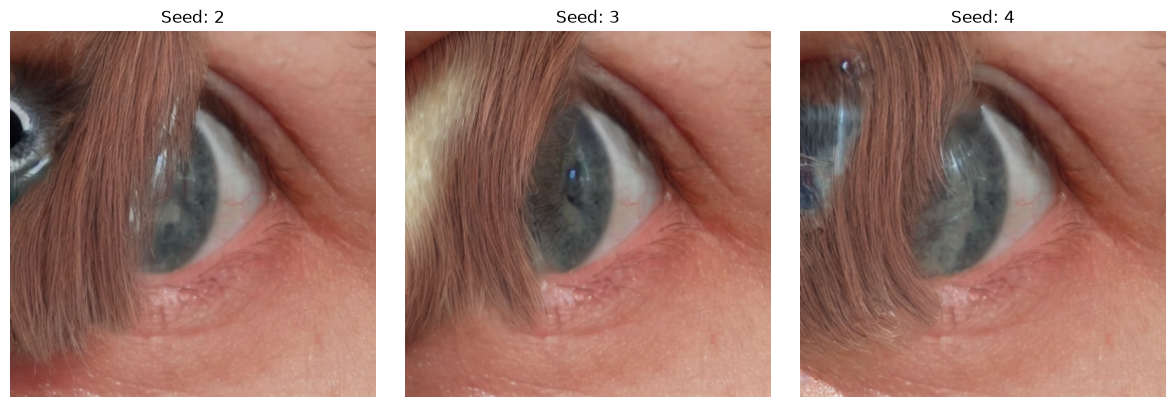

In [119]:
def generate_samples(seeds):
    p, ax = plt.subplots(1, len(seeds), figsize=(len(seeds)*4, 4))
    if len(seeds) == 1:
        ax = [ax]
    for i, s in enumerate(seeds):
        output = inpainter.generate(
            init_image=init_img,
            inpaint_mask=blured_mask,
            attn_mask=attn_msk,
            bg_suppress_bias=bias_func,
            isolate_reference=True,
            top_k_views=100,
            funnel_top_k_views=50,
            funnel_step=10,
            patch_grid_size=6,
            patch_start_step=5,
            num_inference_steps=35,
            switch_step=1,
            guidance_scale=3.5,
            style_fidelity=fidelity_func,
            seed=s,
            prompt="macro closeup photograph of sparse stray hair curl covering an eye, strong shadows",
        )
        ax[i].imshow(output)
        ax[i].axis('off')
        ax[i].set_title(f'Seed: {s}')
    plt.tight_layout()
    return p

generate_samples([2, 3, 4])
plt.show()